## Imports

In [1]:
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
import pandas as pd
import numpy as np
from scipy.stats import entropy, spearmanr
import matplotlib.pyplot as plt
from av2.datasets.motion_forecasting import scenario_serialization
from av2.datasets.motion_forecasting.eval import metrics
import tqdm
import torch
from torch import nn

from tracs.av2.metrics import compute_weighted_metrics

## Load data

In [2]:
backbone = "DeMo"
program_name = "complete2"
use_random_tracs_scores = False

In [3]:
data_root = Path("../data")
val_ground_truth_path = data_root / "av2" / "val_ground_truth.parquet"
test_ground_truth_path = data_root / "av2" / "av2_mf_focal_test_annotations.parquet"
test_prediction_path = data_root / "av2_backbone_outputs" / backbone / "submission_test.parquet"
train_data_path = data_root / "results" / program_name / "val" / backbone / "scored_predictions.parquet"
test_data_path = data_root / "tracs_predictions" / program_name / backbone / "test.parquet"

random_appendix = "_random_tracs_scores" if use_random_tracs_scores else ""
version = "v9"  # for file naming; increment if we want to save new versions of the features/weights/scores files
features_pt_path = data_root / "results" / program_name / "val" / backbone / f"features_{version}{random_appendix}.pt"
optimal_weights_pt_path = data_root / "results" / program_name / "val" / backbone / f"optimal_weights_{version}{random_appendix}.pt"
scores_pt_path = data_root / "results" / program_name / "val" / backbone / f"scores_{version}{random_appendix}.pt"

if use_random_tracs_scores:
    print("WARNING: Using random TraCS scores for ablation study!")

## Data preparation

In [4]:
def get_val_gt_trajectory(scenario_id: str) -> pd.DataFrame:
    scenario_path = data_root / "av2" / "val" / scenario_id / f"scenario_{scenario_id}.parquet"
    scenario = scenario_serialization.load_argoverse_scenario_parquet(scenario_path)
    focal_track = next(t for t in scenario.tracks if t.track_id == scenario.focal_track_id)
    future_states = [s for s in focal_track.object_states if not s.observed]
    gt = np.array([[s.position[0], s.position[1]] for s in future_states])
    return pd.DataFrame({
        "scenario_id": [scenario_id],
        "gt_trajectory_x": [gt[:, 0].tolist()],
        "gt_trajectory_y": [gt[:, 1].tolist()],
    })

In [5]:
def load_scenario_extras(scenario_id: str, split: str = "val"):
    scenario_path = data_root / "av2" / split / scenario_id / f"scenario_{scenario_id}.parquet"
    scenario = scenario_serialization.load_argoverse_scenario_parquet(scenario_path)
    focal_track = next(t for t in scenario.tracks if t.track_id == scenario.focal_track_id)
    past_states = sorted([s for s in focal_track.object_states if s.observed], key=lambda s: s.timestep)
    past_xy = np.array([[s.position[0], s.position[1]] for s in past_states], dtype=np.float64)  # (50, 2)
    n_agents = sum(1 for t in scenario.tracks if any(s.observed for s in t.object_states))
    return past_xy, n_agents

In [6]:
src = data_root / "tracs_predictions" / program_name / backbone / "val.parquet"
train_data = pd.read_parquet(src).drop(columns=[
    "covariance", "is_moving", "min_dist_to_focal",
    "included_in_features", "tracs_backbone_independent_op",
    "tracs_backbone_linear_op", "tracs_pointwise_scores",
])
train_data_path.parent.mkdir(parents=True, exist_ok=True)
train_data.to_parquet(train_data_path)

In [7]:
if not val_ground_truth_path.exists():
    scenario_ids = [p.name for p in (data_root / "av2" / "val").iterdir() if p.is_dir()]
    with ThreadPoolExecutor(8) as pool:
        rows = list(tqdm.tqdm(pool.map(get_val_gt_trajectory, scenario_ids), total=len(scenario_ids)))
    pd.concat(rows, ignore_index=True).to_parquet(val_ground_truth_path)

val_gt = pd.read_parquet(val_ground_truth_path).set_index("scenario_id")

## Fusion Network Architecture

In [8]:
def fuse_classifiers(backbone_log_probs: np.ndarray, tracs_log_probs: np.ndarray, w: np.ndarray, num_outcomes: int = 6, tol: float = 1e-10) -> np.ndarray:
    # Multiplicative non-independent opinion fusion (log-linear pooling):
    # log_fused = w1 * np.log(tracs_probs + tol) + w2 * np.log(backbone_probs + tol)
    # fused_probs = np.exp(log_fused - log_fused.max())  # for numerical stability

    # Log-odds against uniform (pointwise mutual information):
    uniform_log_odds = np.log(1/num_outcomes)
    fused_probs = backbone_log_probs + \
        w[..., None] * (tracs_log_probs - uniform_log_odds)
    # for numerical stability
    fused_probs = np.exp(fused_probs - fused_probs.max())

    # Normalize fused probabilities:
    return fused_probs / fused_probs.sum(axis=-1, keepdims=True)


class FusionNet(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 512), nn.ReLU(),
            nn.Linear(512, 256),       nn.ReLU(),
            nn.Linear(256, 64),        nn.ReLU(),
            nn.Linear(64, 1)           # unconstrained weights
        )

    _AGENT_TYPES = ["vehicle", "bus", "cyclist", "motorcyclist", "pedestrian"]

    @staticmethod
    def extract_features(predicted_tracks, *, focal_type=None, backbone_scores=None,
                         tracs_scores=None, n_agents=None, past_trajectory=None):
        parts = []

        # Predicted trajectory features (always included): (6, 60, 2) → 720 dims
        relative = predicted_tracks - predicted_tracks[:, :1, :]
        # Only take every 10th point to reduce dimensionality
        relative = relative[:, ::10, :]  # Shape: (6, 6, 2) -> 72 dims
        # scale = relative.std() + 1e-6
        # parts.append((relative / scale).flatten().astype(np.float32))
        # Diff removes one more point -> (6, 5, 2) → 60 dims
        parts.append(np.diff(relative, axis=-2).flatten().astype(np.float32))

        # Comment out any line below to disable that feature:
        if focal_type is not None:
            parts.append(
                np.eye(len(FusionNet._AGENT_TYPES), dtype=np.float32)[FusionNet._AGENT_TYPES.index(
                    focal_type) if focal_type in FusionNet._AGENT_TYPES else 0]
            )  # 5 dims
        if backbone_scores is not None:
            scores = np.asarray(backbone_scores, dtype=np.float32)
            parts.append(scores.flatten())  # 6 dims  # Do not sort these!
            parts.append(entropy(scores, base=2)[None])  # 1 dim
        if tracs_scores is not None:
            scores = np.asarray(tracs_scores, dtype=np.float32)
            parts.append(scores.flatten())  # 6 dims  # Do not sort these!
            parts.append(entropy(scores, base=2)[None])  # 1 dim
        if n_agents is not None:
            parts.append(np.array([n_agents], dtype=np.float32))  # 1 dim
        if past_trajectory is not None:  # (n_steps, 2) → 2*n_steps dims
            p = np.asarray(past_trajectory, dtype=np.float32)
            p = p - p[-1:]  # center at last observed position
            p /= (p.std() + 1e-6)
            parts.append(p.flatten())

        return np.concatenate(parts)

    def forward(self, x):
        return self.net(x)[..., 0]

    def predict_weights(self, predicted_tracks, *, focal_type=None, backbone_scores=None,
                        tracs_scores=None, n_agents=None, past_trajectory=None):
        feats = FusionNet.extract_features(
            predicted_tracks, focal_type=focal_type, backbone_scores=backbone_scores,
            tracs_scores=tracs_scores, n_agents=n_agents, past_trajectory=past_trajectory,
        )
        x = torch.tensor(feats).unsqueeze(0).to(next(self.parameters()).device)
        with torch.no_grad():
            return self.forward(x).squeeze(0).cpu().numpy()

## Supervisor

In [9]:
n_weights_grid = 1000

def optimal_weights_grid(log_tracs_scores, log_backbone_scores, predicted_tracks, gt_track, n_grid=n_weights_grid, mode: str="brier_minADE1"):
    """Vectorized grid search over weights."""

    w = np.linspace(0, 1, n_grid)
    # W1, W2 = np.meshgrid(w, w, indexing="ij")
    # W1, W2 = W1.flatten(), W2.flatten()

    fused_probs = fuse_classifiers(log_backbone_scores, log_tracs_scores, w)  # (n_grid, K)
    ade_vector = metrics.compute_ade(predicted_tracks, gt_track)  # (K,)

    match mode:
        # Take the best ADE score among all 6 predicted trajectories
        case "brier_minADE1":
            idx_most_weight = np.argmax(fused_probs, axis=-1)  # (n_grid,)
            selected_probs = np.take_along_axis(fused_probs, idx_most_weight[:, None], axis=1).squeeze(1)
            brier_ade = ade_vector[idx_most_weight] + np.square(1 - selected_probs)  # (n_grid,)

            idx_most_weight_backbone = np.argmax(log_backbone_scores)  # single item
            original_score = ade_vector[idx_most_weight_backbone] + np.square(1 - np.exp(log_backbone_scores[idx_most_weight_backbone]))
        case "brier_minADE6":
            raise NotImplementedError("brier_minADE6 not implemented yet")

    # Take the best weight and corresponding optimized score
    best_weight_idx = np.argmin(brier_ade)
    optimal_score = brier_ade[best_weight_idx]

    return w[best_weight_idx], original_score, optimal_score

## Training

In [10]:
train_data = pd.read_parquet(train_data_path)

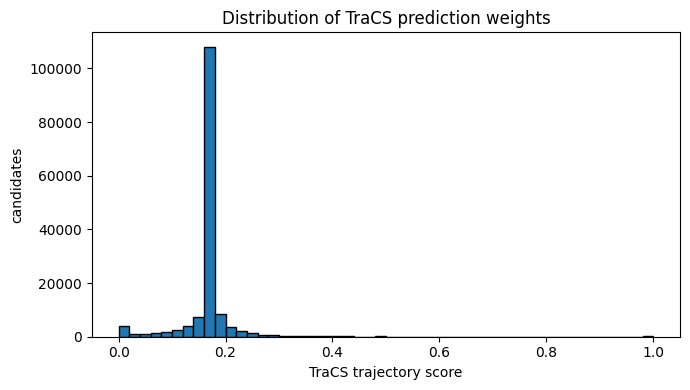

mean=0.1667  std=0.0651  min=0.0000  p25=0.1666  p50=0.1667  p75=0.1677  max=1.0000


In [11]:
tracs_scores = train_data["tracs_trajectory_score"].values.reshape(-1, 6)

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(tracs_scores.flatten(), bins=50, edgecolor="black")
ax.set_xlabel("TraCS trajectory score")
ax.set_ylabel("candidates")
ax.set_title("Distribution of TraCS prediction weights")
plt.tight_layout()
plt.show()

v = tracs_scores.flatten()
print(f"mean={v.mean():.4f}  std={v.std():.4f}  min={v.min():.4f}  "
      f"p25={np.percentile(v,25):.4f}  p50={np.percentile(v,50):.4f}  "
      f"p75={np.percentile(v,75):.4f}  max={v.max():.4f}")

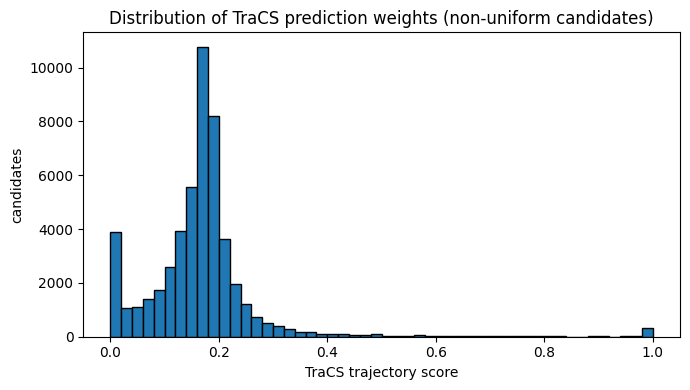

mean=0.1667  std=0.1120  min=0.0000  p25=0.1255  p50=0.1715  p75=0.1926  max=1.0000


In [12]:
tracs_scores_nonuniform = tracs_scores[tracs_scores.std(axis=1) > 0.01, :].flatten()

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(tracs_scores_nonuniform, bins=50, edgecolor="black")
ax.set_xlabel("TraCS trajectory score")
ax.set_ylabel("candidates")
ax.set_title("Distribution of TraCS prediction weights (non-uniform candidates)")
plt.tight_layout()
plt.show()

v = tracs_scores_nonuniform
print(f"mean={v.mean():.4f}  std={v.std():.4f}  min={v.min():.4f}  "
      f"p25={np.percentile(v,25):.4f}  p50={np.percentile(v,50):.4f}  "
      f"p75={np.percentile(v,75):.4f}  max={v.max():.4f}")

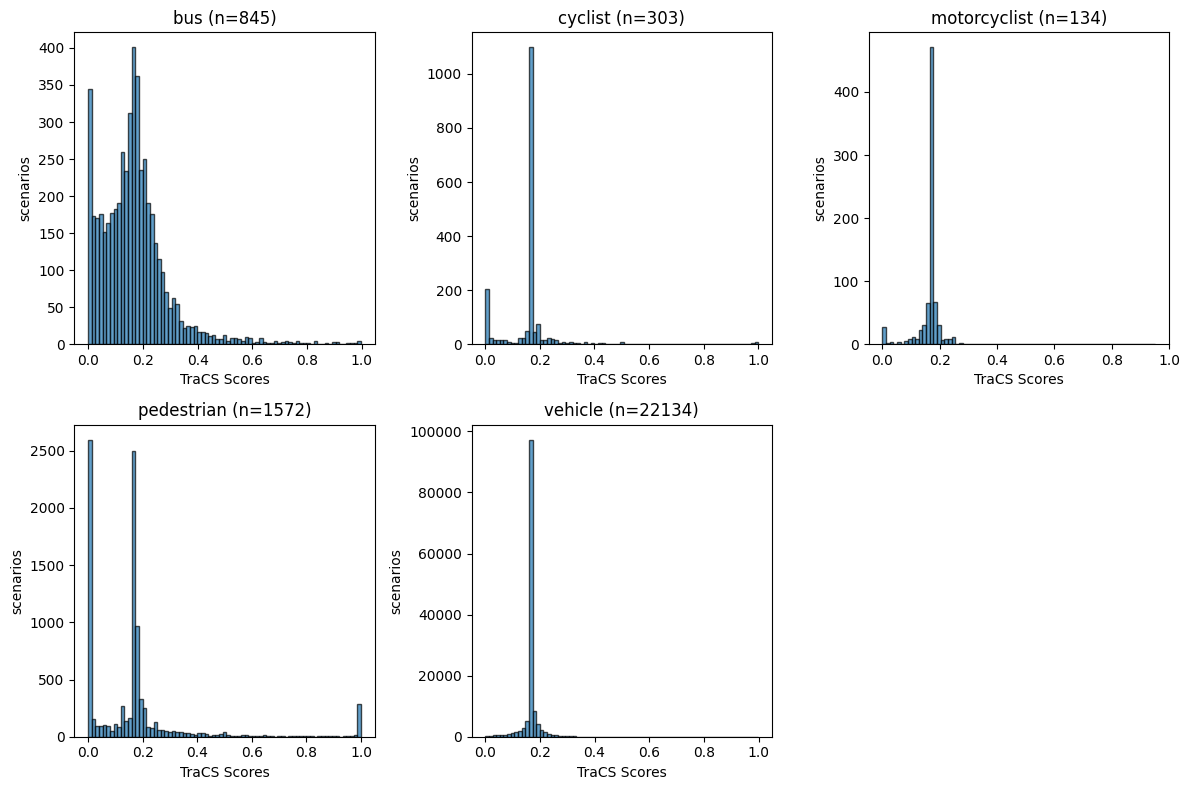

In [13]:
# The same plot as before but split by vehicle type
plt.figure(figsize=(12, 8))
agent_types = train_data["agent_type"].values[::6]
for i, vtype in enumerate(sorted(set(agent_types))):
    plt.subplot(2, 3, i+1)
    mask = agent_types == vtype
    agent_tracs_scores = tracs_scores[mask, :]
    plt.hist(agent_tracs_scores.flatten(), bins=75, edgecolor="black", alpha=0.7)
    plt.xlabel("TraCS Scores")
    plt.ylabel("scenarios")
    plt.title(f"{vtype} (n={mask.sum()})")
plt.tight_layout()
plt.show()

In [14]:
def _process_scenario(args):
    scenario_id, scenario_data = args
    gt_row = val_gt.loc[scenario_id]
    gt_track = np.stack([
        np.array(gt_row["gt_trajectory_x"]),
        np.array(gt_row["gt_trajectory_y"])
    ], axis=1).astype(np.float64)

    log_tracs_scores = np.log(np.array(scenario_data["tracs_trajectory_score"]) + 1e-10)
    log_backbone_scores = np.log(np.array(scenario_data["backbone_trajectory_score"]) + 1e-10)
    predicted_tracks = np.moveaxis(
        np.array([[*scenario_data["x_traj"]], [*scenario_data["y_traj"]]]),
        source=[0, 1, 2], destination=[2, 0, 1],
    ).astype(np.float64)

    # For ablation: use random TraCS scores instead of the actual ones
    if use_random_tracs_scores and entropy(scenario_data["tracs_trajectory_score"], base=2) < 0.95 * entropy([1/6]*6, base=2):
        log_tracs_scores = np.random.choice(np.arange(6), replace=False, size=6).astype(np.float64)
        log_tracs_scores /= log_tracs_scores.sum()  # normalize to sum to 1
        log_tracs_scores = np.log(log_tracs_scores + 1e-10)

    # past_xy, n_agents = load_scenario_extras(scenario_id, split="val")
    w, original_score, optimal_score = optimal_weights_grid(log_tracs_scores, log_backbone_scores, predicted_tracks, gt_track)

    features = FusionNet.extract_features(
        predicted_tracks,
        focal_type=scenario_data["agent_type"].iloc[0],
        backbone_scores=np.array(scenario_data["backbone_trajectory_score"]),
        tracs_scores=np.array(scenario_data["tracs_trajectory_score"]),
        # n_agents=n_agents,
        # past_trajectory=past_xy,
    )
    return features, w, original_score, optimal_score


if not features_pt_path.exists() or not optimal_weights_pt_path.exists() or not scores_pt_path.exists():
    groups = list(train_data.groupby("scenario_id"))
    with ThreadPoolExecutor(8) as pool:
        results = list(tqdm.tqdm(pool.map(_process_scenario, groups), total=len(groups)))

    all_features, all_weights, all_original_scores, all_optimal_scores = zip(*results)
    F = torch.tensor(np.stack(all_features), dtype=torch.float32)
    W = torch.tensor(np.array(all_weights), dtype=torch.float32)
    all_original_scores = torch.tensor(np.array(all_original_scores), dtype=torch.float32)
    all_optimal_scores = torch.tensor(np.array(all_optimal_scores), dtype=torch.float32)
    print(f"Dataset: {F.shape} features, {W.shape} labels")

    torch.save(F, features_pt_path)
    torch.save(W, optimal_weights_pt_path)
    torch.save((all_original_scores, all_optimal_scores), scores_pt_path)

else:
    F = torch.load(features_pt_path, weights_only=True)
    W = torch.load(optimal_weights_pt_path, weights_only=True)
    all_original_scores, all_optimal_scores = torch.load(scores_pt_path)

    F.shape, W.shape, len(all_original_scores), len(all_optimal_scores)

100%|██████████| 24988/24988 [01:09<00:00, 357.80it/s]


Dataset: torch.Size([24988, 79]) features, torch.Size([24988]) labels


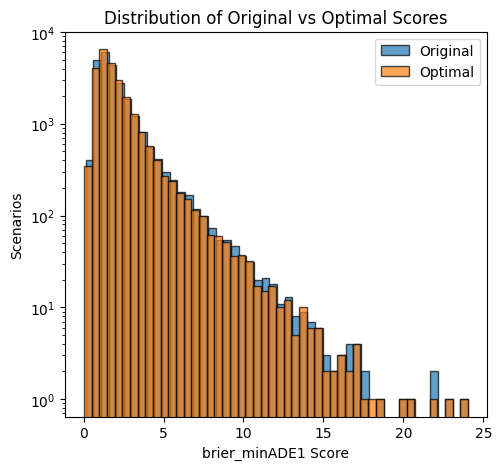

Original scores: mean=2.1705, std=1.7059
Optimal scores: mean=2.0840, std=1.6482
Improvement: mean=0.0864, std=0.4347


In [15]:
# Show histogram of original and optimal scores
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(all_original_scores, bins=50, alpha=0.7, label="Original", edgecolor="black", log=True)
plt.hist(all_optimal_scores, bins=50, alpha=0.7, label="Optimal", edgecolor="black", log=True)
plt.xlabel("brier_minADE1 Score")
plt.ylabel("Scenarios")
plt.title("Distribution of Original vs Optimal Scores")
plt.legend()
plt.show()

print(f"Original scores: mean={np.mean(all_original_scores.numpy()):.4f}, std={np.std(all_original_scores.numpy()):.4f}")
print(f"Optimal scores: mean={np.mean(all_optimal_scores.numpy()):.4f}, std={np.std(all_optimal_scores.numpy()):.4f}")
print(f"Improvement: mean={np.mean(np.array(all_original_scores.numpy()) - np.array(all_optimal_scores.numpy())):.4f}, "
        f"std={np.std(np.array(all_original_scores.numpy()) - np.array(all_optimal_scores.numpy())):.4f}")


bus - Improvement: mean=0.0751, std=0.3960
cyclist - Improvement: mean=0.0851, std=0.3632
motorcyclist - Improvement: mean=0.0921, std=0.2944
pedestrian - Improvement: mean=0.1026, std=0.6922
vehicle - Improvement: mean=0.0857, std=0.4135


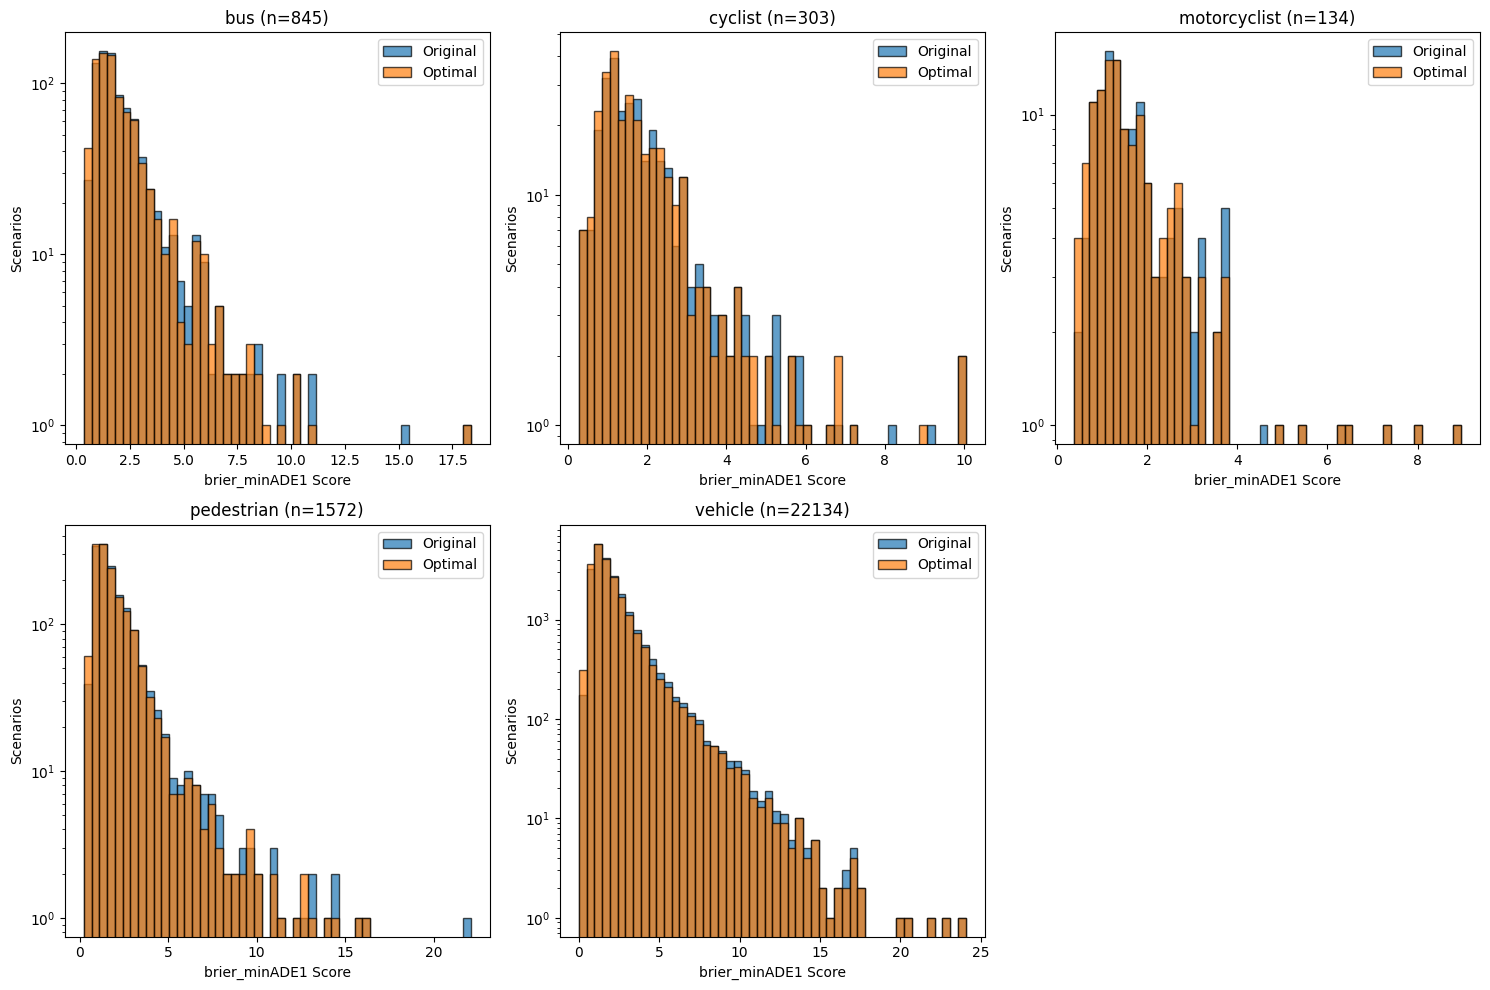

In [16]:
# the same per agent type
agent_types = train_data["agent_type"].values[::6]
plt.figure(figsize=(15, 10))
for i, vtype in enumerate(sorted(set(agent_types))):
    plt.subplot(2, 3, i+1)
    mask = agent_types == vtype
    bins = np.histogram_bin_edges(
        np.concatenate([all_original_scores.numpy()[mask], all_optimal_scores.numpy()[mask]]),
        bins=50,
    )
    plt.hist(all_original_scores.numpy()[mask], bins=bins, alpha=0.7, label="Original", edgecolor="black", log=True)
    plt.hist(all_optimal_scores.numpy()[mask], bins=bins, alpha=0.7, label="Optimal", edgecolor="black", log=True)
    plt.xlabel("brier_minADE1 Score")
    plt.ylabel("Scenarios")
    plt.title(f"{vtype} (n={mask.sum()})")
    plt.legend()
    print(f"{vtype} - Improvement: mean={np.mean(all_original_scores.numpy()[mask] - all_optimal_scores.numpy()[mask]):.4f}, "
          f"std={np.std(all_original_scores.numpy()[mask] - all_optimal_scores.numpy()[mask]):.4f}")
plt.tight_layout()
plt.show()

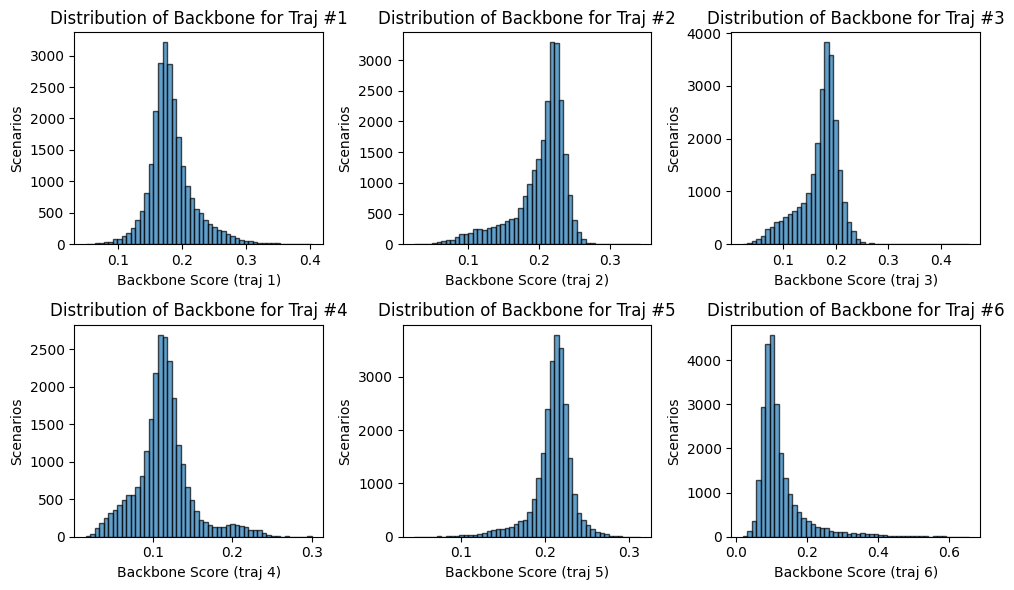

In [17]:
all_backbone_scores = train_data["backbone_trajectory_score"].to_numpy().reshape(-1, 6)

# show average score per each of six indices (shared axes)
plt.figure(figsize=(10, 6))
plt.subplot(2, 3, 1)
for i in range(6):
    plt.subplot(2, 3, i+1)
    plt.hist(all_backbone_scores[:, i], bins=50, edgecolor="black", alpha=0.7)
    plt.xlabel(f"Backbone Score (traj {i+1})")
    plt.ylabel("Scenarios")
    plt.title(f"Distribution of Backbone for Traj #{i+1}")
plt.tight_layout()

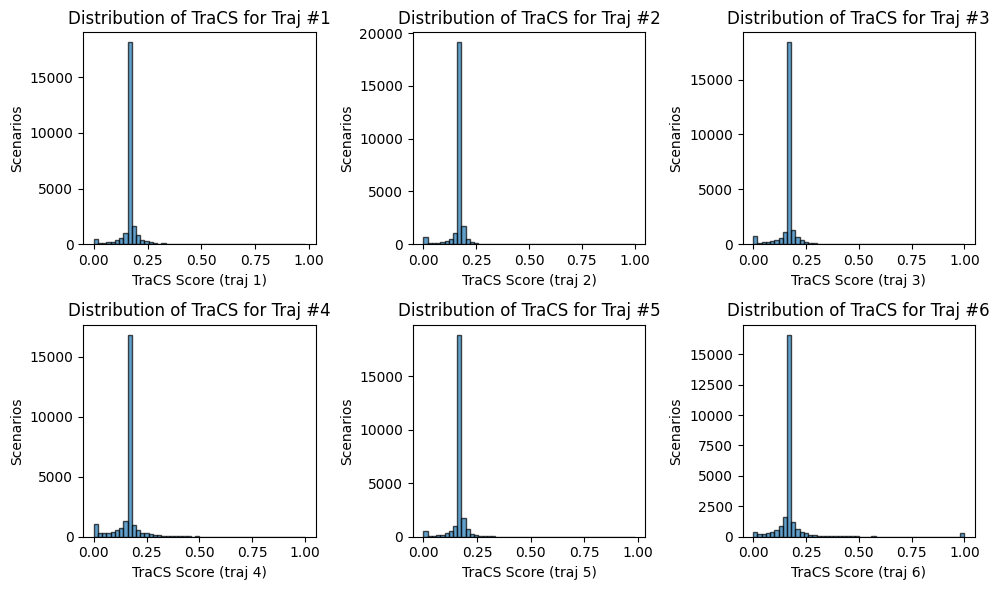

In [18]:
all_traj_scores = train_data["tracs_trajectory_score"].to_numpy().reshape(-1, 6)

# show average score per each of six indices (shared axes)
plt.figure(figsize=(10, 6))
plt.subplot(2, 3, 1)
for i in range(6):
    plt.subplot(2, 3, i+1)
    plt.hist(all_traj_scores[:, i], bins=50, edgecolor="black", alpha=0.7)
    plt.xlabel(f"TraCS Score (traj {i+1})")
    plt.ylabel("Scenarios")
    plt.title(f"Distribution of TraCS for Traj #{i+1}")
plt.tight_layout()

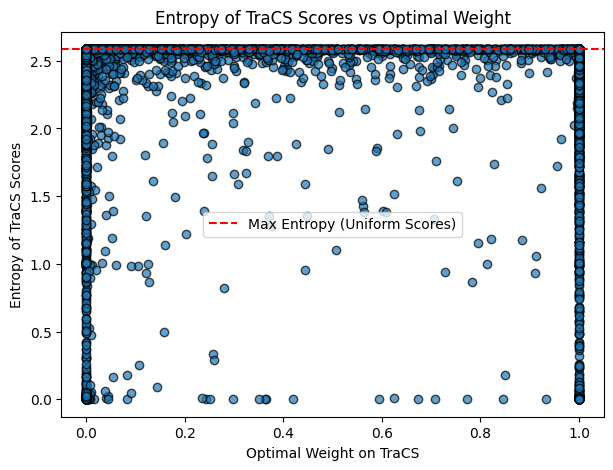

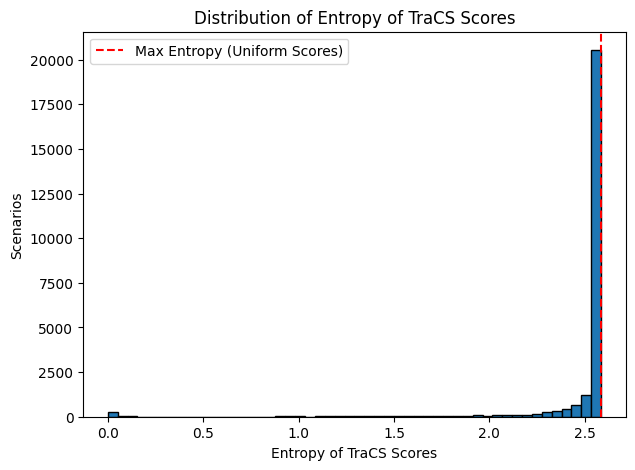

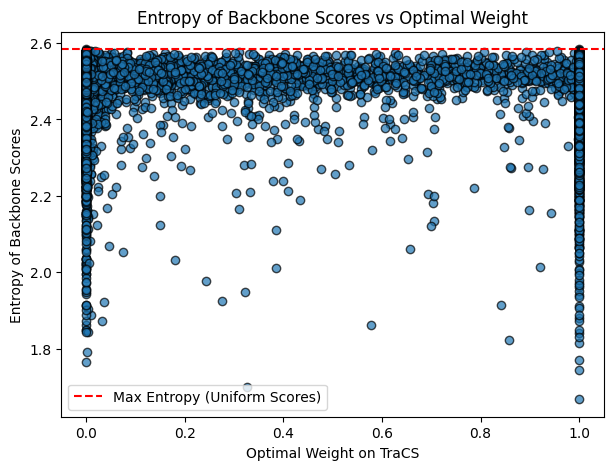

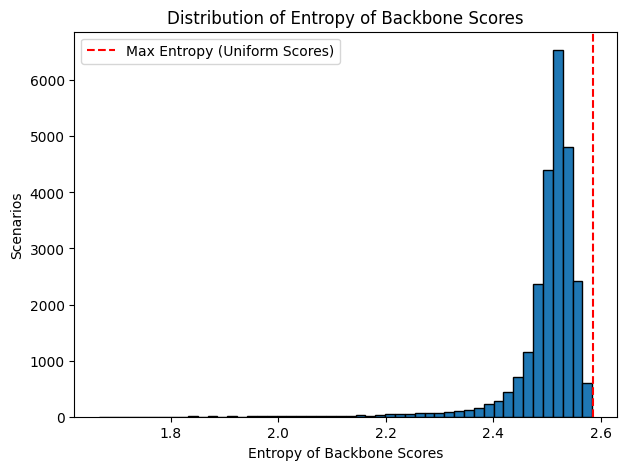

In [19]:
# Show how W correlates with entropy of TraCS scores

entropies_tracs = entropy(train_data["tracs_trajectory_score"].to_numpy().reshape(-1, 6), base=2, axis=-1)
plt.figure(figsize=(7, 5))
plt.scatter(W.cpu().numpy(), entropies_tracs, alpha=0.7, edgecolor="black")
plt.xlabel("Optimal Weight on TraCS")
plt.ylabel("Entropy of TraCS Scores")
plt.axhline(entropy([1/6]*6, base=2), color="red", linestyle="--", label="Max Entropy (Uniform Scores)")
plt.legend()
plt.title("Entropy of TraCS Scores vs Optimal Weight")
plt.show()

plt.figure(figsize=(7, 5))
plt.hist(entropies_tracs, bins=50, edgecolor="black")
plt.xlabel("Entropy of TraCS Scores")
plt.ylabel("Scenarios")
plt.title("Distribution of Entropy of TraCS Scores")
plt.axvline(entropy([1/6]*6, base=2), color="red", linestyle="--", label="Max Entropy (Uniform Scores)")
plt.legend()
plt.show()

entropies_backbone = entropy(train_data["backbone_trajectory_score"].to_numpy().reshape(-1, 6), base=2, axis=-1)
plt.figure(figsize=(7, 5))
plt.scatter(W.cpu().numpy(), entropies_backbone, alpha=0.7, edgecolor="black")
plt.xlabel("Optimal Weight on TraCS")
plt.ylabel("Entropy of Backbone Scores")
plt.axhline(entropy([1/6]*6, base=2), color="red", linestyle="--", label="Max Entropy (Uniform Scores)")
plt.legend()
plt.title("Entropy of Backbone Scores vs Optimal Weight")
plt.show()

plt.figure(figsize=(7, 5))
plt.hist(entropies_backbone, bins=50, edgecolor="black")
plt.xlabel("Entropy of Backbone Scores")
plt.ylabel("Scenarios")
plt.title("Distribution of Entropy of Backbone Scores")
plt.axvline(entropy([1/6]*6, base=2), color="red", linestyle="--", label="Max Entropy (Uniform Scores)")
plt.legend()
plt.show()

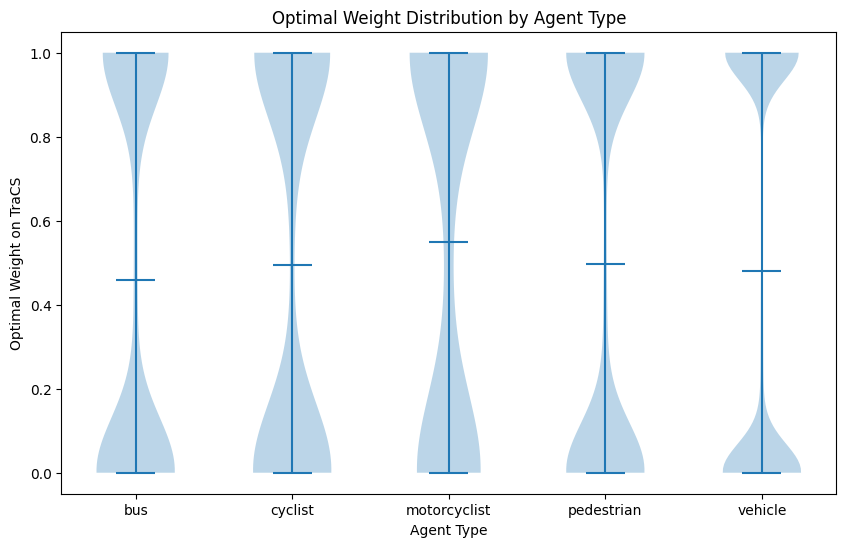

In [20]:
# Show weight distribution by agent type as violin plot

plt.figure(figsize=(10, 6))
agent_types = train_data["agent_type"].values[::6]
plt.violinplot([W[agent_types == vtype].cpu().numpy() for vtype in sorted(set(agent_types))], showmeans=True)
plt.xticks(ticks=np.arange(1, len(set(agent_types))+1), labels=sorted(set(agent_types)))
plt.xlabel("Agent Type")
plt.ylabel("Optimal Weight on TraCS")
plt.title("Optimal Weight Distribution by Agent Type")
plt.show()

/tmp/ipykernel_3074509/3242498761.py:2: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  spearman_scores = np.array([spearmanr(all_backbone_scores[i], all_traj_scores[i]).correlation for i in range(len(all_backbone_scores))])


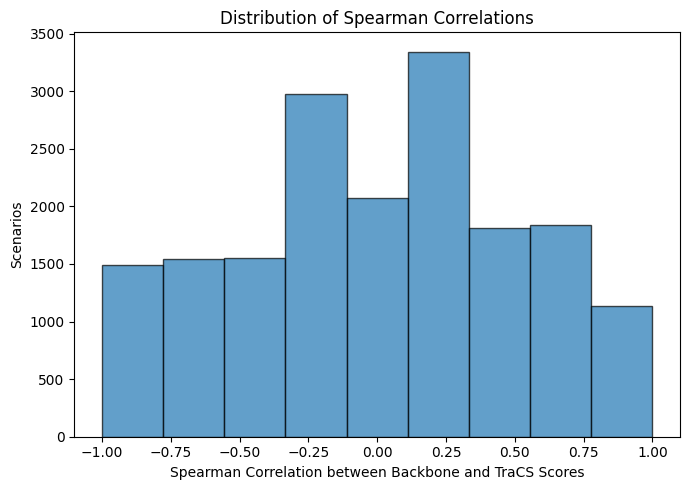

In [21]:
# plot hist over spearmans (each spearman is only over the six trajectories, i.e., axis #1 not axis #0) between backbone and tracs scores
spearman_scores = np.array([spearmanr(all_backbone_scores[i], all_traj_scores[i]).correlation for i in range(len(all_backbone_scores))])
plt.figure(figsize=(7, 5))
plt.hist(spearman_scores, bins=9, edgecolor="black", alpha=0.7)
plt.xlabel("Spearman Correlation between Backbone and TraCS Scores")
plt.ylabel("Scenarios")
plt.title("Distribution of Spearman Correlations")
plt.tight_layout()
plt.show()

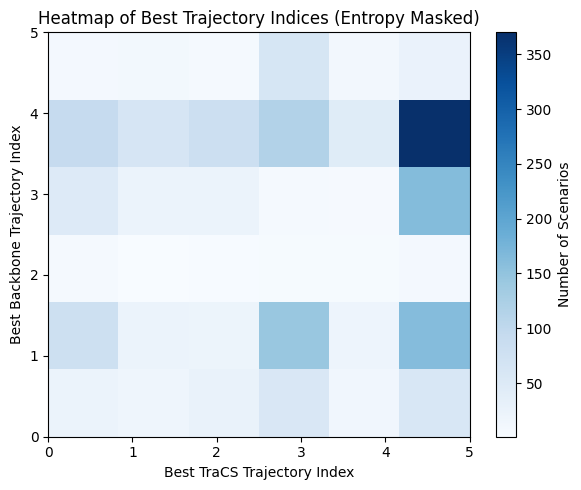

7.415559468544902

In [22]:
idx_best_traj = tracs_scores.argmax(axis=-1)
# idx_best_traj = np.random.randint(0, 6, size=all_traj_scores.shape[0])  # for testing the heatmap with random indices
idx_best_score = all_backbone_scores.argmax(axis=-1)

mask = entropy(tracs_scores, base=2, axis=-1) < 0.9 * entropy([1/6]*6, base=2)
plt.figure(figsize=(6, 5))
plt.hist2d(idx_best_traj[mask], idx_best_score[mask], bins=6, range=[[0, 5], [0, 5]], cmap="Blues")
plt.xlabel("Best TraCS Trajectory Index")
plt.ylabel("Best Backbone Trajectory Index")
plt.title("Heatmap of Best Trajectory Indices (Entropy Masked)")
plt.colorbar(label="Number of Scenarios")
plt.tight_layout()
plt.show()

# show percentage of retained scenarios after applying the entropy-based mask
mask.sum().item() / len(mask) * 100

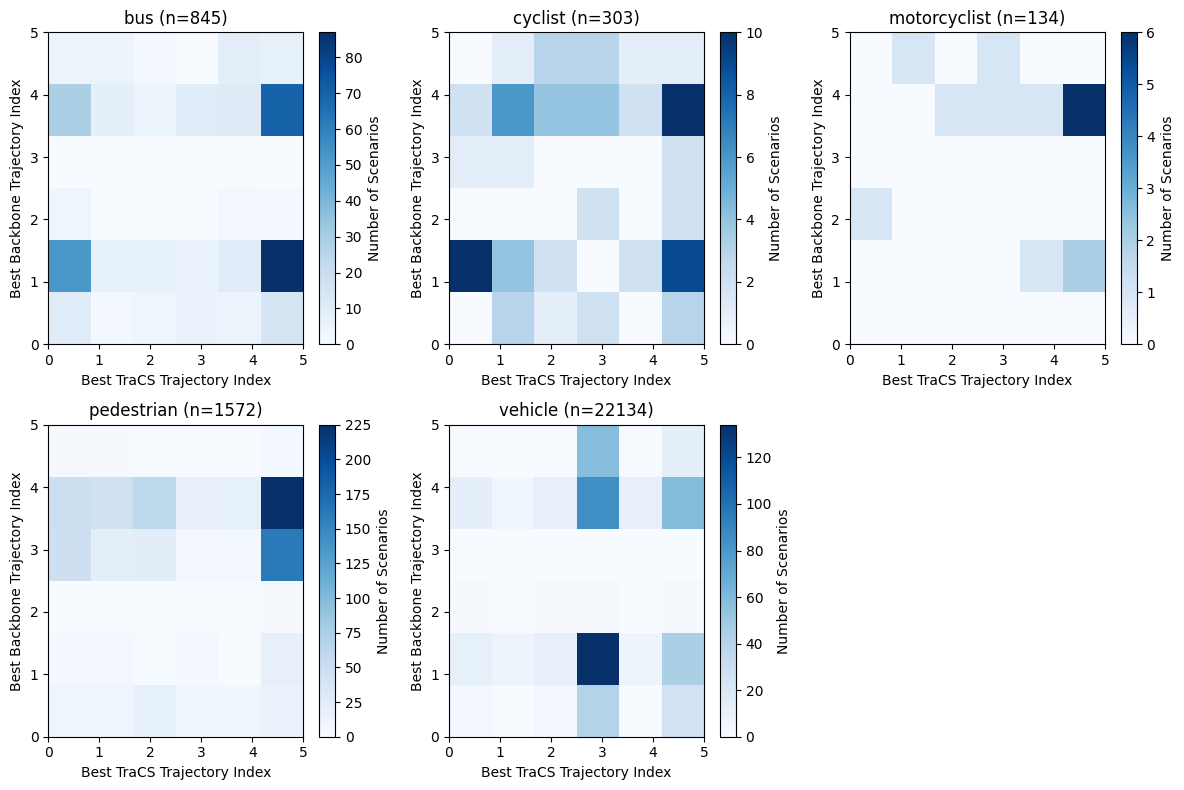

In [23]:
# same per agent type

agent_types = train_data["agent_type"].values[::6]
plt.figure(figsize=(12, 8))
for i, vtype in enumerate(sorted(set(agent_types))):
    plt.subplot(2, 3, i+1)
    vtype_mask = agent_types == vtype
    mask = (entropy(tracs_scores[vtype_mask], base=2, axis=-1) < 0.9 * entropy([1/6]*6, base=2))
    plt.hist2d(idx_best_traj[vtype_mask][mask], idx_best_score[vtype_mask][mask], bins=6, range=[[0, 5], [0, 5]], cmap="Blues")
    plt.xlabel("Best TraCS Trajectory Index")
    plt.ylabel("Best Backbone Trajectory Index")
    plt.title(f"{vtype} (n={vtype_mask.sum()})")
    plt.colorbar(label="Number of Scenarios")
plt.tight_layout()
plt.show()

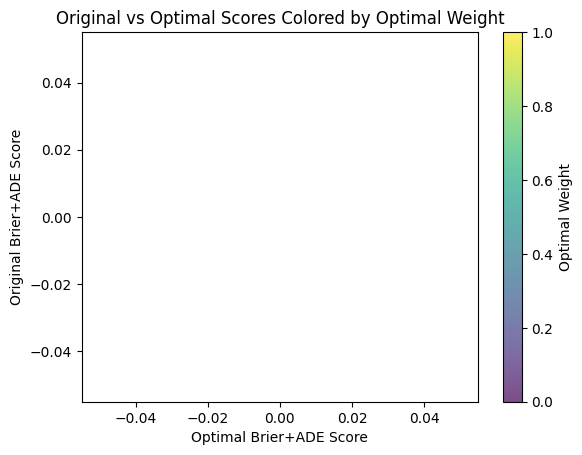

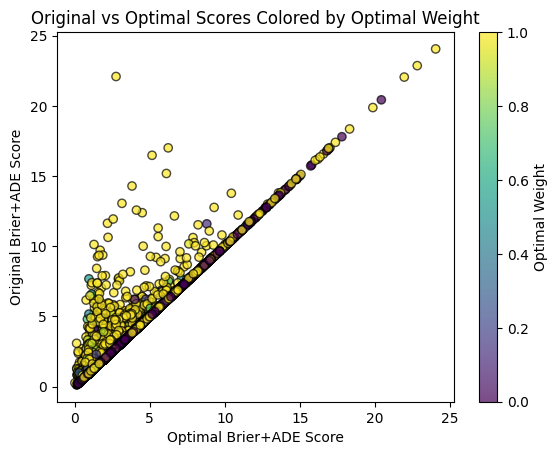

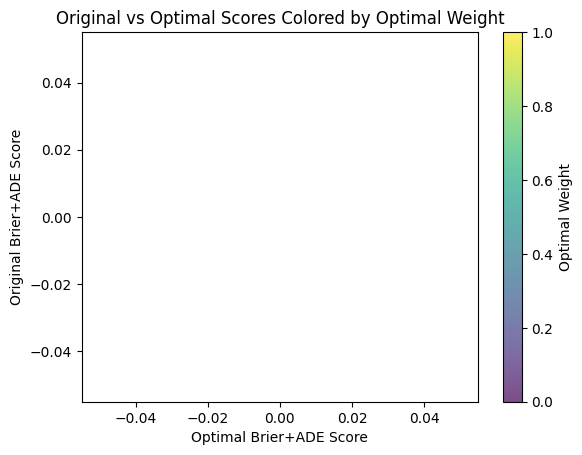

In [24]:
mask = (W < -1)
plt.scatter(all_optimal_scores[mask], all_original_scores[mask], alpha=0.7, edgecolor="black", c=W[mask])
plt.xlabel("Optimal Brier+ADE Score")
plt.ylabel("Original Brier+ADE Score")
plt.title("Original vs Optimal Scores Colored by Optimal Weight")
plt.colorbar(label="Optimal Weight")
plt.show()

mask = (W.abs() <= 1)
plt.scatter(all_optimal_scores[mask], all_original_scores[mask], alpha=0.7, edgecolor="black", c=W[mask])
plt.xlabel("Optimal Brier+ADE Score")
plt.ylabel("Original Brier+ADE Score")
plt.title("Original vs Optimal Scores Colored by Optimal Weight")
plt.colorbar(label="Optimal Weight")
plt.show()

mask = (W > 1)
plt.scatter(all_optimal_scores[mask], all_original_scores[mask], alpha=0.7, edgecolor="black", c=W[mask])
plt.xlabel("Optimal Brier+ADE Score")
plt.ylabel("Original Brier+ADE Score")
plt.title("Original vs Optimal Scores Colored by Optimal Weight")
plt.colorbar(label="Optimal Weight")
plt.show()

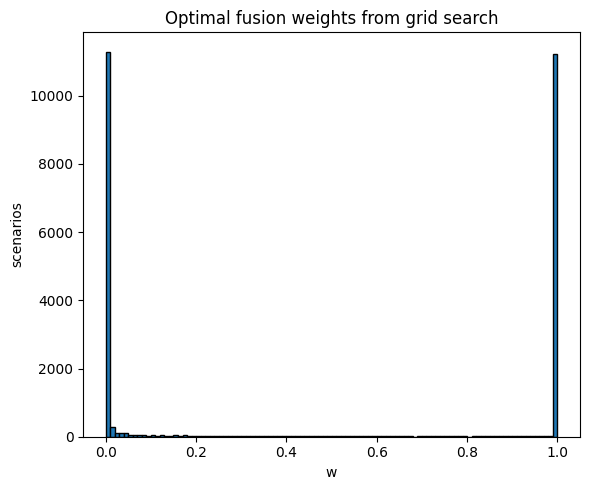

                      mean     std     min     p25     p50     p75     max
 0.481   0.486   0.000   0.000   0.221   1.000   1.000


In [25]:
w_np = W.cpu().numpy()
fig, ax = plt.subplots(figsize=(6, 5))
plt.hist(w_np, bins=100, edgecolor="black")
ax.set_xlabel("w")
ax.set_ylabel("scenarios")
ax.set_title("Optimal fusion weights from grid search")
plt.tight_layout()
plt.show()

header = f"{'':18s}  {'mean':>6}  {'std':>6}  {'min':>6}  {'p25':>6}  {'p50':>6}  {'p75':>6}  {'max':>6}"
print(header)
print(f"{w_np.mean():6.3f}  {w_np.std():6.3f}  {w_np.min():6.3f}  "
        f"{np.percentile(w_np,25):6.3f}  {np.percentile(w_np,50):6.3f}  "
        f"{np.percentile(w_np,75):6.3f}  {w_np.max():6.3f}")

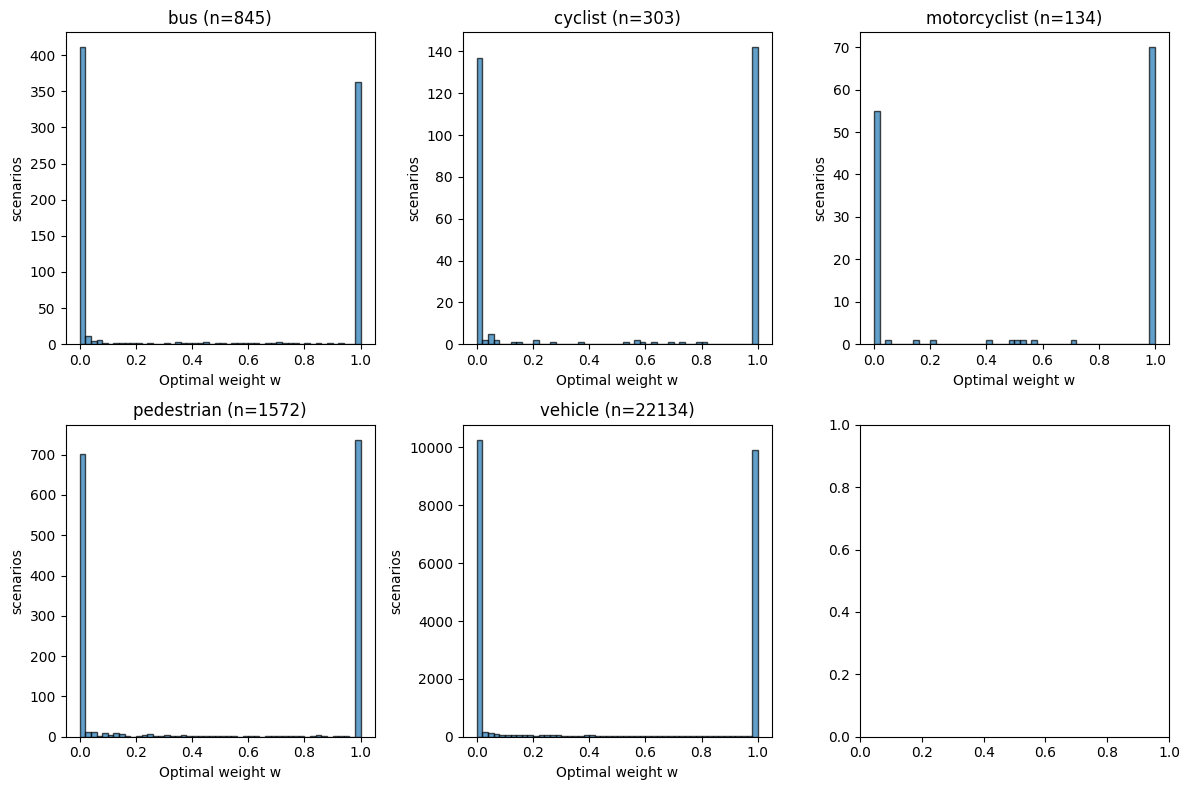

In [26]:
# now split by agent type since some types have very few samples (e.g. bus)
plt.subplots(2, 3, figsize=(12, 8))
agent_types = train_data["agent_type"].values[::6]
for i, vtype in enumerate(sorted(set(agent_types))):
    plt.subplot(2, 3, i+1)
    mask = agent_types == vtype
    plt.hist(w_np[mask], bins=50, edgecolor="black", alpha=0.7)
    plt.xlabel("Optimal weight w")
    plt.ylabel("scenarios")
    plt.title(f"{vtype} (n={mask.sum()})")
plt.tight_layout()
plt.show()

In [27]:
# TODO show the above without the uniform cases

In [29]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
F, W = F.to(device), W.to(device)

# Deterministic 80/20 train/val split by scenario index
g = torch.Generator(device="cpu").manual_seed(0)
perm = torch.randperm(len(F), generator=g)
n_val = int(0.1 * len(F))
val_idx = perm[:n_val].to(device)
train_idx = perm[n_val:].to(device)
F_tr, W_tr = F[train_idx], W[train_idx]
F_va, W_va = F[val_idx], W[val_idx]
print(f"Train: {len(F_tr)}  Val: {len(F_va)}")

# F_tr, W_tr = F_tr[:256, :], W_tr[:256]

n_epochs = 300
model = FusionNet(F.shape[1]).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
# optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3) #, weight_decay=1e-4
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)

train_losses= []
val_losses = []
for epoch in range(n_epochs):
    model.train()
    for idx in torch.randperm(len(F_tr)).split(256):
        optimizer.zero_grad()
        nn.functional.mse_loss(model(F_tr[idx]), W_tr[idx]).backward()
        optimizer.step()
    scheduler.step()
    if epoch % 50 == 0 or epoch == n_epochs - 1:
        model.eval()
        with torch.no_grad():
            tr_loss = nn.functional.mse_loss(model(F_tr), W_tr).item()
            va_loss = nn.functional.mse_loss(model(F_va), W_va).item()
            w_pred_tr = model(F_tr).cpu().numpy()
            w_pred_va = model(F_va).cpu().numpy()
            train_losses.append(tr_loss)
            val_losses.append(va_loss)
            print(f"Epoch {epoch:3d}: train={tr_loss:.4f} (rmse={tr_loss**0.5:.4f})  "
                  f"val={va_loss:.4f} (rmse={va_loss**0.5:.4f})  mean w_tr={w_pred_tr.mean():.4f}  mean w_va={w_pred_va.mean():.4f}")

Train: 22490  Val: 2498
Epoch   0: train=0.2374 (rmse=0.4873)  val=0.2388 (rmse=0.4887)  mean w_tr=0.4510  mean w_va=0.4510
Epoch  50: train=0.2103 (rmse=0.4586)  val=0.2181 (rmse=0.4670)  mean w_tr=0.5135  mean w_va=0.5148
Epoch 100: train=0.1925 (rmse=0.4387)  val=0.2172 (rmse=0.4661)  mean w_tr=0.4681  mean w_va=0.4659
Epoch 150: train=0.1721 (rmse=0.4149)  val=0.2170 (rmse=0.4658)  mean w_tr=0.4864  mean w_va=0.4866
Epoch 200: train=0.1556 (rmse=0.3945)  val=0.2256 (rmse=0.4749)  mean w_tr=0.4632  mean w_va=0.4622
Epoch 250: train=0.1399 (rmse=0.3740)  val=0.2299 (rmse=0.4795)  mean w_tr=0.4691  mean w_va=0.4685
Epoch 299: train=0.1352 (rmse=0.3676)  val=0.2315 (rmse=0.4812)  mean w_tr=0.4812  mean w_va=0.4812


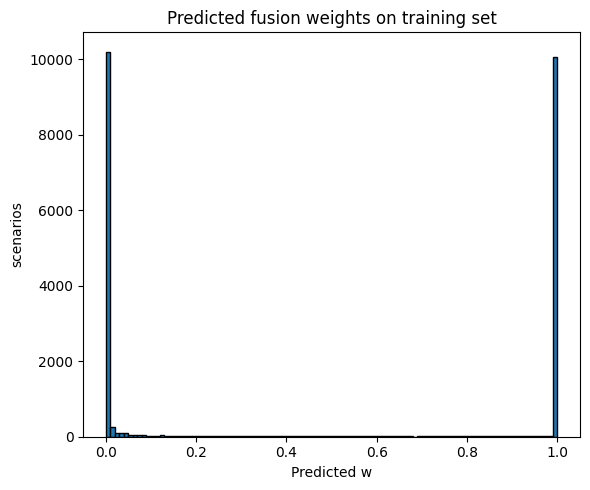

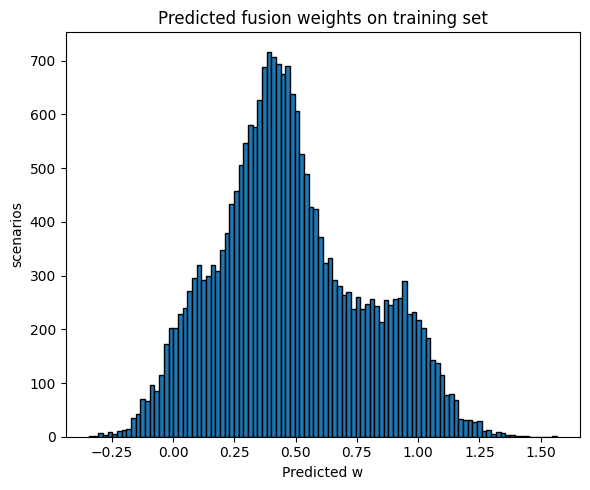

In [ ]:
# histogram over w_pred_tr
fig, ax = plt.subplots(figsize=(6, 5))
plt.hist(W_tr.cpu().numpy(), bins=100, edgecolor="black")
ax.set_xlabel("Predicted w")
ax.set_ylabel("scenarios")
ax.set_title("True fusion weights on training set")
plt.tight_layout()
plt.show()

# histogram over w_pred_tr
fig, ax = plt.subplots(figsize=(6, 5))
plt.hist(w_pred_tr, bins=100, edgecolor="black")
ax.set_xlabel("Predicted w")
ax.set_ylabel("scenarios")
ax.set_title("Predicted fusion weights on training set")
plt.tight_layout()
plt.show()

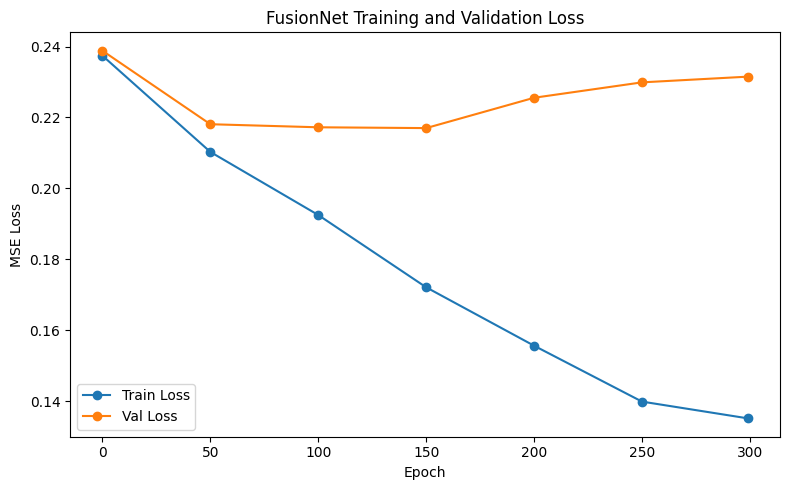

In [31]:
# Plot training and validation loss curves
plt.figure(figsize=(8, 5))
plt.plot(list(range(0, n_epochs, 50)) + [n_epochs-1], train_losses, marker='o', label='Train Loss')
plt.plot(list(range(0, n_epochs, 50)) + [n_epochs-1], val_losses, marker='o', label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.title('FusionNet Training and Validation Loss')
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
test_data = pd.read_parquet(test_data_path)
ground_truth = pd.read_parquet(test_ground_truth_path)
rows = []

for scenario_id in tqdm.tqdm(test_data["scenario_id"].unique()):  # TODO remove debugging slice
    gt_row = ground_truth[ground_truth["scenario_id"] == scenario_id]
    gt_track = np.stack([
        np.array(gt_row["gt_trajectory_x"].iloc[0]),
        np.array(gt_row["gt_trajectory_y"].iloc[0])
    ], axis=1).astype(np.float64)

    scenario_data = test_data[test_data["scenario_id"] == scenario_id]
    backbone_probs = np.array(scenario_data["backbone_trajectory_score"], dtype=np.float64)
    tracs_scores = np.array(scenario_data["tracs_trajectory_score"], dtype=np.float64)
    predicted_tracks = np.moveaxis(
        np.array([[*scenario_data["x_traj"]], [*scenario_data["y_traj"]]]),
        source=[0, 1, 2], destination=[2, 0, 1],
    ).astype(np.float64)

    focal_type = scenario_data["agent_type"].iloc[0]
    # past_xy, n_agents = load_scenario_extras(scenario_id, split="test")

    # Backbone only
    backbone_probs_norm = backbone_probs / backbone_probs.sum()

    # FusionNet
    w = model.predict_weights(
        predicted_tracks,
        focal_type=focal_type,
        backbone_scores=backbone_probs,
        tracs_scores=tracs_scores,
        # n_agents=n_agents,
        # past_trajectory=past_xy,
    )
    # w = w.round()
    # w = w.clip(0, None)
    # if w < 0.1:
    #     w = np.array(0)
    fused_probs = fuse_classifiers(np.log(backbone_probs + 1e-10), np.log(tracs_scores + 1e-10), w)

    # Full AV2 metric set: per-trajectory arrays are shared across weightings
    ade_arr = metrics.compute_ade(predicted_tracks, gt_track)
    fde_arr = metrics.compute_fde(predicted_tracks, gt_track)
    is_missed_arr = metrics.compute_is_missed_prediction(predicted_tracks, gt_track)
    backbone_av2 = compute_weighted_metrics(predicted_tracks, gt_track, backbone_probs_norm, ade_arr, fde_arr, is_missed_arr)
    fusion_av2 = compute_weighted_metrics(predicted_tracks, gt_track, fused_probs, ade_arr, fde_arr, is_missed_arr)

    main_criterion = "brier_minADE1"
    rows.append({
        "scenario_id": scenario_id,
        "agent_type": focal_type,
        "weight": float(w),
        "tracs_scores": tracs_scores,
        **{f"backbone_{k}": v for k, v in backbone_av2.items()},
        **{f"fusion_{k}": v for k, v in fusion_av2.items()},
        "backbone_score": backbone_av2[main_criterion],
        "fusion_score": fusion_av2[main_criterion],
    })

results = pd.DataFrame(rows)
results["delta"] = results["fusion_score"] - results["backbone_score"]

# Categorize per-scenario change as improved / same / degraded (used by the summary and plots).
_tol = 1e-3
results["category"] = pd.Categorical(
    np.select(
        [results["delta"] < -_tol, results["delta"] > _tol],
        ["improved", "degraded"],
        default="same",
    ),
    categories=["improved", "same", "degraded"],
    ordered=True,
)

# Relative entropy of the TraCS distribution (confidence proxy used by downstream plots).
_tracs_arr = np.stack(results["tracs_scores"].to_list())
_uniform_entropy = 6 * -(1/6 * np.log(1/6))
results["tracs_rel_entropy"] = -np.sum(_tracs_arr * np.log(_tracs_arr + 1e-10), axis=1) - _uniform_entropy

 26%|██▌       | 6518/24984 [01:04<03:00, 102.42it/s]

In [ ]:
# Table 1: Brier-minADE summary (overall + per vehicle type)
print(f"Backbone   Brier-minADE: {results['backbone_score'].mean():.4f}")
print(f"FusionNet  Brier-minADE: {results['fusion_score'].mean():.4f}")
print(f"Delta: {results['delta'].mean():.4f}  ({(results['fusion_score'].mean() / results['backbone_score'].mean() - 1) * 100:.1f}%)")
vtypes = sorted(results["agent_type"].unique())
balanced_delta = sum(
    results.loc[results["agent_type"] == vt, "delta"].mean() for vt in vtypes
) / len(vtypes)
print(f"Balanced Delta (avg of per-type deltas): {balanced_delta:.4f}")

print("\nPer vehicle type:")
for vtype in vtypes:
    sub = results[results["agent_type"] == vtype]
    b = sub["backbone_score"].to_numpy()
    f = sub["fusion_score"].to_numpy()
    imp = sub["category"] == "improved"
    same = sub["category"] == "same"
    deg = sub["category"] == "degraded"
    d_improved = sub.loc[imp, "delta"].to_numpy()
    d_degraded = sub.loc[deg, "delta"].to_numpy()
    n = len(sub)
    print(f"  {vtype:14s}  n={n:5d}  Backbone={b.mean():.4f}  FusionNet={f.mean():.4f}  "
          f"Delta={f.mean()-b.mean():+.4f} ({(f.mean()/b.mean()-1)*100:+.1f}%)  "
          f"Improved={imp.sum()/n*100:.1f}%  Same={same.sum()/n*100:.1f}%  Degraded={deg.sum()/n*100:.1f}%  "
          f"Delta(improved)={d_improved.mean():.4f} ({d_improved.mean()/(b[imp].mean())*100:.1f}%)  "
          f"Delta(degraded)={d_degraded.mean():.4f} ({d_degraded.mean()/(b[deg].mean())*100:.1f}%)  "
          f"q90_improvement={np.percentile(f, 90)-np.percentile(b, 90):.4f}")

# Table 2: Full AV2 metrics (overall + per vehicle type)
av2_metric_names = [c[len("backbone_"):] for c in results.columns
                    if c.startswith("backbone_") and c != "backbone_score"]

def _print_av2_table(subset, label):
    print(f"\nFull AV2 metrics — {label}:")
    print(f"  {'metric':<25s} {'Backbone':>10s} {'FusionNet':>10s} {'Delta':>10s}")
    for m in av2_metric_names:
        b = subset[f"backbone_{m}"].mean()
        f = subset[f"fusion_{m}"].mean()
        delta = f - b
        delta_percent = (f / b - 1) * 100
        print(f"  {m:<25s} {b:>10.4f} {f:>10.4f} {delta:>+10.4f} ({delta_percent:>+4.1f}%)")

_print_av2_table(results, f"overall (n={len(results)})")
for vtype in vtypes:
    sub = results[results["agent_type"] == vtype]
    _print_av2_table(sub, f"{vtype} (n={len(sub)})")

In [ ]:
# Histogram of deltas
plt.figure(figsize=(7, 4))
plt.hist(results.loc[results["category"] == "improved", "delta"], bins=100, edgecolor="black", color="green", alpha=0.7, label="Improved")
plt.hist(results.loc[results["category"] == "degraded", "delta"], bins=100, edgecolor="black", color="red", alpha=0.7, label="Degraded")
plt.xlabel("FusionNet Brier-minADE - Backbone Brier-minADE")
plt.ylabel("scenarios")
plt.title("Distribution of per-scenario Brier-minADE improvement")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# The same plot as before but split by vehicle type
plt.figure(figsize=(12, 8))
for i, vtype in enumerate(sorted(results["agent_type"].unique())):
    plt.subplot(2, 3, i+1)
    sub = results[results["agent_type"] == vtype]
    plt.hist(sub.loc[sub["category"] == "improved", "delta"], bins=30, edgecolor="black", color="green", alpha=0.7, label="Improved")
    plt.hist(sub.loc[sub["category"] == "degraded", "delta"], bins=30, edgecolor="black", color="red", alpha=0.7, label="Degraded")
    plt.xlabel("FusionNet Brier-minADE - Backbone Brier-minADE")
    plt.ylabel("scenarios")
    plt.title(f"{vtype} (n={len(sub)})")
    plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Plot weight distribution of NN outputs
plt.hist(results["weight"], bins=100, edgecolor="black")
plt.xlabel("FusionNet predicted weights")
plt.ylabel("scenarios")
plt.title(f"Distribution of FusionNet predicted weights on test set (n={len(results)})")
plt.tight_layout()
plt.show()

In [ ]:
# Plot weights vs improvement per agent type
plt.figure(figsize=(7, 5))
for vtype in sorted(results["agent_type"].unique()):
    if vtype == "vehicle":
        continue
    sub = results[results["agent_type"] == vtype]
    plt.scatter(sub["weight"], sub["delta"], alpha=0.7, edgecolor="black", label=vtype)
plt.xlabel("FusionNet predicted weight w")
plt.ylabel("Brier-minADE improvement (FusionNet - Backbone)")
plt.title("FusionNet predicted weight vs improvement over backbone")
plt.axhline(0, color="black", linestyle="--")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Make the same as a KDE plot since the scatter is very noisy
import seaborn as sns
plt.figure(figsize=(7, 5))
for vtype in sorted(results["agent_type"].unique()):
    if vtype == "vehicle":
        continue
    sub = results[results["agent_type"] == vtype]
    sns.kdeplot(x=sub["weight"], y=sub["delta"], fill=True, alpha=0.7, label=vtype)
plt.xlabel("FusionNet predicted weight w")
plt.ylabel("Brier-minADE improvement (FusionNet - Backbone)")
plt.title("FusionNet predicted weight vs improvement over backbone (KDE)")
plt.axhline(0, color="black", linestyle="--")
# add a linear regression line to the scatter plot
sns.regplot(x=results["weight"], y=results["delta"], scatter=False, color="black", label="Overall trend")
plt.legend(title="Agent type")
plt.tight_layout()
plt.show()

In [ ]:
# Plot weights vs entropy of the TraCS distribution (as a proxy for confidence) per agent type
plt.figure(figsize=(7, 5))
for vtype in sorted(results["agent_type"].unique()):
    if vtype == "vehicle":
        continue
    sub = results[results["agent_type"] == vtype]
    plt.scatter(sub["weight"], sub["tracs_rel_entropy"], alpha=0.7, edgecolor="black", label=vtype)
plt.xlabel("FusionNet predicted weight w")
plt.ylabel("Relative Entropy of TraCS Distribution")
plt.title("FusionNet predicted weight vs relative entropy of TraCS distribution")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Plot delta vs entropy of the TraCS distribution (as a proxy for confidence) per agent type
plt.figure(figsize=(7, 5))
for vtype in sorted(results["agent_type"].unique()):
    if vtype == "vehicle":
        continue
    sub = results[results["agent_type"] == vtype]
    plt.scatter(sub["delta"], sub["tracs_rel_entropy"], alpha=0.7, edgecolor="black", label=vtype)
plt.axvline(0, color="black", linestyle="--")
plt.xlabel("Brier-minADE improvement (FusionNet - Backbone)")
plt.ylabel("Relative Entropy of TraCS Distribution")
plt.title("Brier-minADE improvement vs relative entropy of TraCS distribution")
plt.legend()
plt.tight_layout()
plt.show()